In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/PRJNA598080")
initial_meta<-read.csv("SraRunTable.csv",header = T)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibraryLayout,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR10802220,AMPLICON,502,31185746,PRJNA598080,SAMN13698109,Metagenome or environmental,20336927,KAZAN FEDERAL UNIVERSITY,2017,⋯,PAIRED,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2020-06-01T00:00:00Z,2019-12-30T03:05:00Z,1,hc10,SRP239030
2,SRR10802221,AMPLICON,502,31370482,PRJNA598080,SAMN13698108,Metagenome or environmental,20552061,KAZAN FEDERAL UNIVERSITY,2017,⋯,PAIRED,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2020-06-01T00:00:00Z,2019-12-30T03:05:00Z,1,hc09,SRP239030
3,SRR10802222,AMPLICON,502,27567832,PRJNA598080,SAMN13698107,Metagenome or environmental,17972062,KAZAN FEDERAL UNIVERSITY,2017,⋯,PAIRED,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2020-06-01T00:00:00Z,2019-12-30T03:05:00Z,1,hc08,SRP239030
4,SRR10802223,AMPLICON,502,27206894,PRJNA598080,SAMN13698106,Metagenome or environmental,17761549,KAZAN FEDERAL UNIVERSITY,2017,⋯,PAIRED,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2020-06-01T00:00:00Z,2019-12-30T03:05:00Z,1,hc07,SRP239030
5,SRR10802224,AMPLICON,502,27061314,PRJNA598080,SAMN13698105,Metagenome or environmental,17574876,KAZAN FEDERAL UNIVERSITY,2017,⋯,PAIRED,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2020-06-01T00:00:00Z,2019-12-30T03:05:00Z,1,hc06,SRP239030
6,SRR10802225,AMPLICON,502,27286712,PRJNA598080,SAMN13698104,Metagenome or environmental,17706987,KAZAN FEDERAL UNIVERSITY,2017,⋯,PAIRED,PCR,METAGENOMIC,human oral metagenome,ILLUMINA,2020-06-01T00:00:00Z,2019-12-30T03:05:00Z,1,hc05,SRP239030


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "Instrument"                     "isolation_source"              
[21] "lat_lon"                        "Library.Name"                  
[23] "LibraryLayout"                  "LibrarySelection"              
[25] "LibrarySource"                  "Organism"                      
[27] "Platform"                       "ReleaseDate"                   
[29] "create_date"                    "version"                       
[31] "Sample.Name"                    "SRA.Study"

In [3]:
 uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = "V3-V4",
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$create_date,
    PCR_primers = 'F: CCTACGGGNGGCWGCAG; R: GACTACHVGGGTATCTAATCC',
    title = 'Comparison of the Microbiota and Inorganic Anion Content in the Saliva of Patients with Gastroesophageal Reflux Disease and Gastroesophageal Reflux Disease-Free Individuals',
    Disease_study = "YES",
    matched_samples = 'NO'
)
uniform_meta$Status <- NA

In [4]:
# 根据样本名称设置状态
for (i in 1:nrow(uniform_meta)) {
    sample_name <- uniform_meta$sample_name[i]
    
    if (grepl("hc", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- "GERD-free"
    } else if (grepl("rd", sample_name, ignore.case = TRUE)) {
        uniform_meta$Status[i] <- "GERD"
    }
    # 如果不匹配任何模式，保持为NA
}
print(length(unique(uniform_meta$Run)))

print(length(unique(uniform_meta$sample_name)))

[1] 26
[1] 26


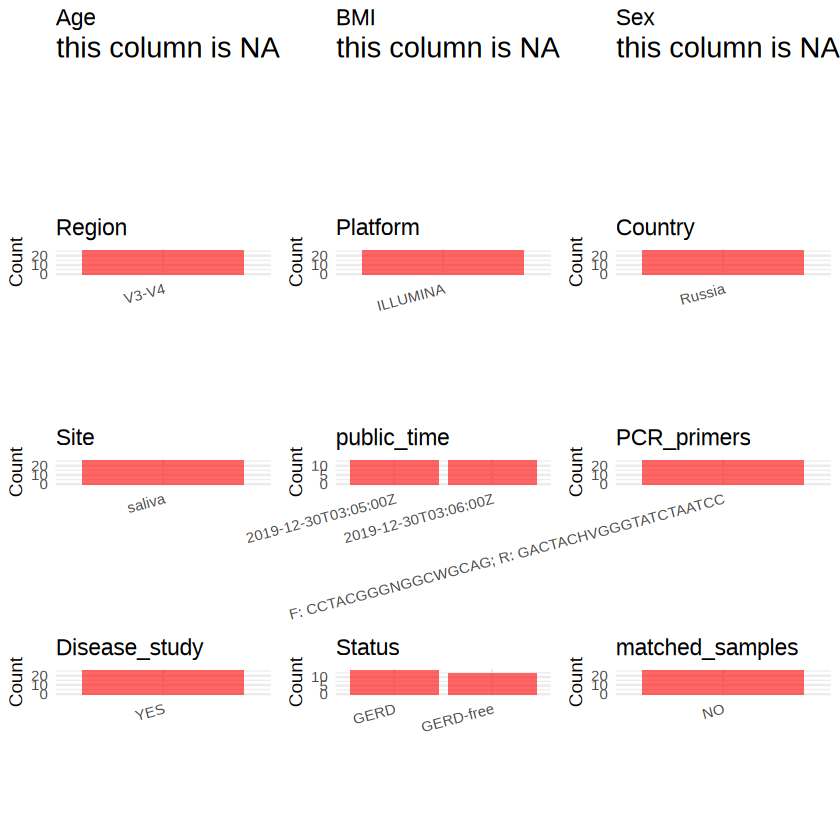

In [5]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)
create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    # Check if the column is all NA
    if (all(is.na(data[[col]]))) {
      # Create an empty plot with text indicating all NA
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      # Numeric variable: histogram
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      # Categorical variable: bar plot (remove NA values)
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  
  return(plots)
}
plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [6]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/PRJNA598080/metadata.csv", quote = F)